In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix




In [3]:
# Loading and inspecting dataset
df = pd.read_csv(r"C:\Users\Admin\Desktop\iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


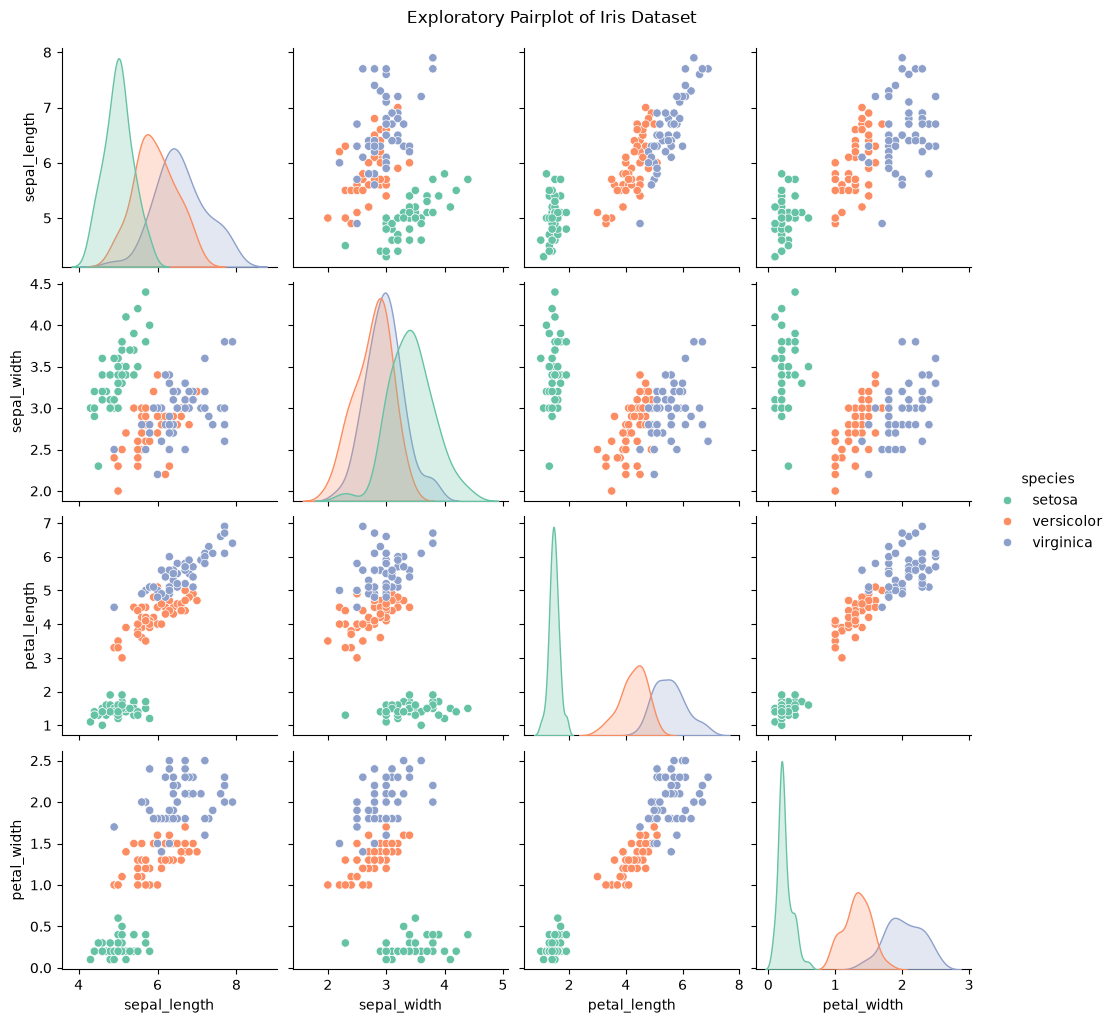

In [5]:
#  Exploratory pairplot grouped by species
sns.pairplot(df, hue='species', palette='Set2', diag_kind='kde')
plt.suptitle("Exploratory Pairplot of Iris Dataset", y=1.02)
plt.show()


In [6]:
# Setting up features and target
X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['species']

# Splitting my dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardizing of the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data preprocessing complete: Train/Test Split (80/20) and StandardScaler applied.")


Data preprocessing complete: Train/Test Split (80/20) and StandardScaler applied.


In [7]:
# Train Logistic Regression
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
lr_preds = lr_model.predict(X_test_scaled)

# Train Decision Tree Classifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_preds = dt_model.predict(X_test_scaled)

# Print Benchmark Reports
print("="*60)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, lr_preds))

print("="*60)
print("DECISION TREE CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, dt_preds))


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



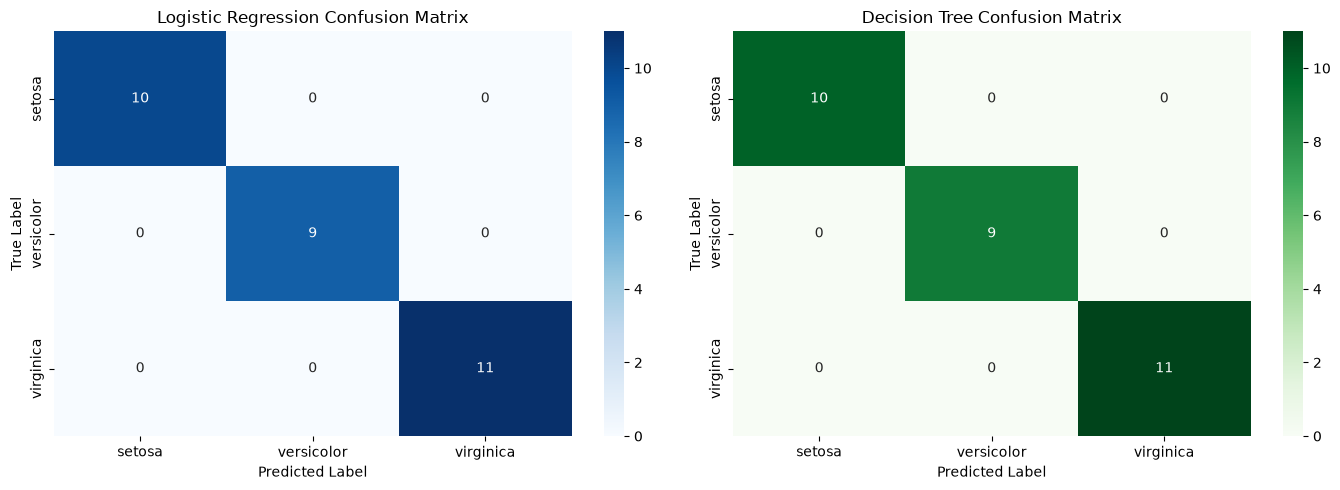

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Heatmap
cm_lr = confusion_matrix(y_test, lr_preds)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=lr_model.classes_, yticklabels=lr_model.classes_)
axes[0].set_title('Logistic Regression Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Decision Tree Heatmap
cm_dt = confusion_matrix(y_test, dt_preds)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=dt_model.classes_, yticklabels=dt_model.classes_)
axes[1].set_title('Decision Tree Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()


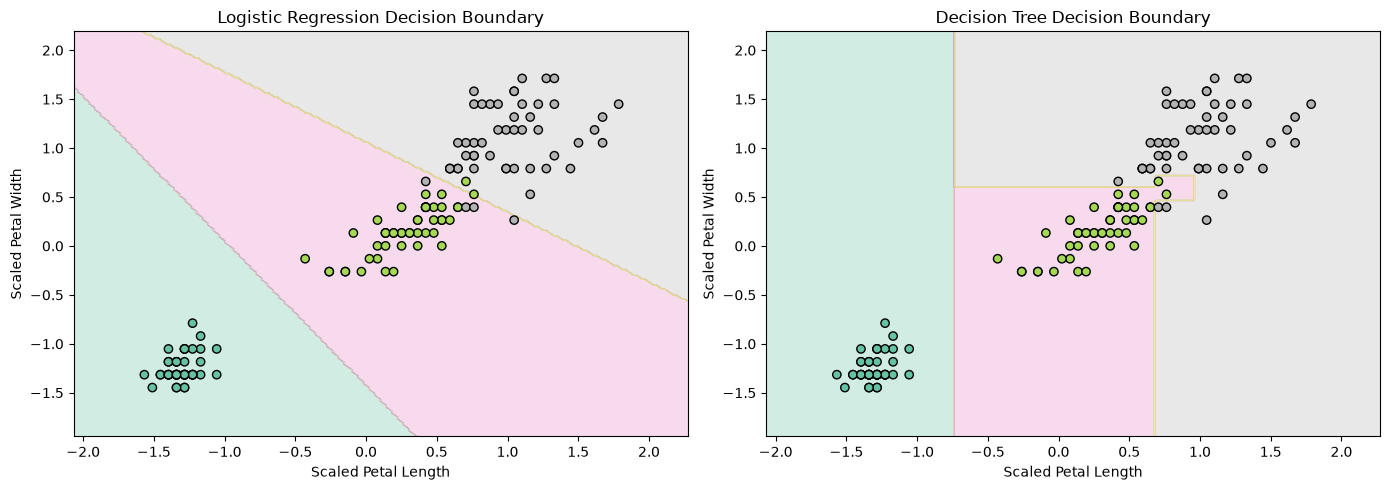

In [9]:
#  visualization boundaries using 2 features: petal_length and petal_width
X_vis = df[['petal_length', 'petal_width']].values
# Mapping species names to numeric values for drawing maps smoothly
species_map = {name: idx for idx, name in enumerate(df['species'].unique())}
y_vis = df['species'].map(species_map).values

# Re-training simpler models on just these two features for visualization purposes
scaler_vis = StandardScaler()
X_vis_scaled = scaler_vis.fit_transform(X_vis)

lr_vis = LogisticRegression(random_state=42).fit(X_vis_scaled, y_vis)
dt_vis = DecisionTreeClassifier(random_state=42).fit(X_vis_scaled, y_vis)

# Creation of mesh grid for plotting bounds
x_min, x_max = X_vis_scaled[:, 0].min() - 0.5, X_vis_scaled[:, 0].max() + 0.5
y_min, y_max = X_vis_scaled[:, 1].min() - 0.5, X_vis_scaled[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = [lr_vis, dt_vis]
titles = ['Logistic Regression Decision Boundary', 'Decision Tree Decision Boundary']

for ax, model, title in zip(axes, models, titles):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Plotting of decision fields
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='Set2')
    
    # Overlaying of actual scatter points
    scatter = ax.scatter(X_vis_scaled[:, 0], X_vis_scaled[:, 1], c=y_vis, edgecolors='k', cmap='Set2')
    ax.set_title(title)
    ax.set_xlabel('Scaled Petal Length')
    ax.set_ylabel('Scaled Petal Width')

plt.tight_layout()
plt.show()
